In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay)

In [5]:
df = pd.read_csv("../data/flood_features.csv", parse_dates=["timestamp"])

targets = [c for c in df.columns if c.startswith(("flood_next", "onset_next"))]
drop_cols = ["timestamp", "station_id", "station_name", "district", "river",
             "latitude", "longitude", "month", "hour", "wind_direction_deg",
             "water_level_m", "danger_level_m",
             "flood_occurred", "flood_severity", "flood_extent_km2"]
features = [c for c in df.columns if c not in drop_cols + targets]
print("Shape:", df.shape, "| Features:", len(features))

Shape: (86520, 73) | Features: 52


In [6]:
TARGET = "onset_next_24h"      # early warning (main)
# TARGET = "flood_next_24h"    # easy target - to run this, remove # and put # on the line above

In [7]:
train = df[df["timestamp"] < "2023-12-29"]
val   = df[(df["timestamp"] >= "2024-01-01") & (df["timestamp"] < "2024-06-28")]
test  = df[df["timestamp"] >= "2024-07-01"]

X_train, X_val, X_test = train[features], val[features], test[features]
y_train, y_val, y_test = train[TARGET], val[TARGET], test[TARGET]

print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)
print(f"{TARGET} = 1 in train: {y_train.mean()*100:.2f}% | test: {y_test.mean()*100:.2f}%")

Train: (42600, 52) | Val: (21480, 52) | Test: (21720, 52)
onset_next_24h = 1 in train: 1.57% | test: 1.69%


In [8]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

In [9]:
results = []

def evaluate(name, prob_val, prob_test):
    # best threshold on VALIDATION data
    best_t, best_f1 = 0.5, -1
    for t in np.arange(0.01, 1.00, 0.01):
        f1 = f1_score(y_val, (prob_val >= t).astype(int), zero_division=0)
        if f1 > best_f1:
            best_t, best_f1 = t, f1

    # final scores on TEST data
    pred = (prob_test >= best_t).astype(int)
    row = {"Model": name,
           "Threshold": round(best_t, 2),
           "Accuracy": accuracy_score(y_test, pred),
           "Precision": precision_score(y_test, pred, zero_division=0),
           "Recall": recall_score(y_test, pred, zero_division=0),
           "F1": f1_score(y_test, pred, zero_division=0),
           "ROC-AUC": roc_auc_score(y_test, prob_test),
           "PR-AUC": average_precision_score(y_test, prob_test)}

    results[:] = [r for r in results if r["Model"] != name]   # re-run safe
    results.append(row)

    for k, v in row.items():
        print(f"{k:10s}: {v:.3f}" if isinstance(v, float) else f"{k:10s}: {v}")
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["No", "Yes"]).plot(cmap="Blues")
    plt.title(f"{name} - {TARGET}")
    plt.show()

Model     : Rule (baseline)
Threshold : 0.010
Accuracy  : 0.662
Precision : 0.000
Recall    : 0.000
F1        : 0.000
ROC-AUC   : 0.337
PR-AUC    : 0.017


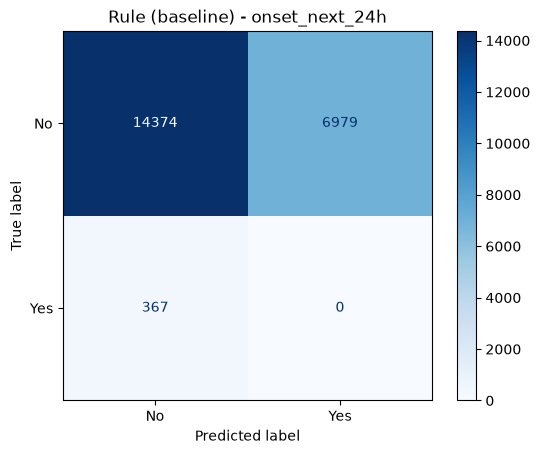

In [10]:
rule_prob_val  = (val["level_gap"] >= 0).astype(float).values
rule_prob_test = (test["level_gap"] >= 0).astype(float).values
evaluate("Rule (baseline)", rule_prob_val, rule_prob_test)

Model     : Logistic Regression
Threshold : 0.960
Accuracy  : 0.978
Precision : 0.170
Recall    : 0.084
F1        : 0.113
ROC-AUC   : 0.968
PR-AUC    : 0.216


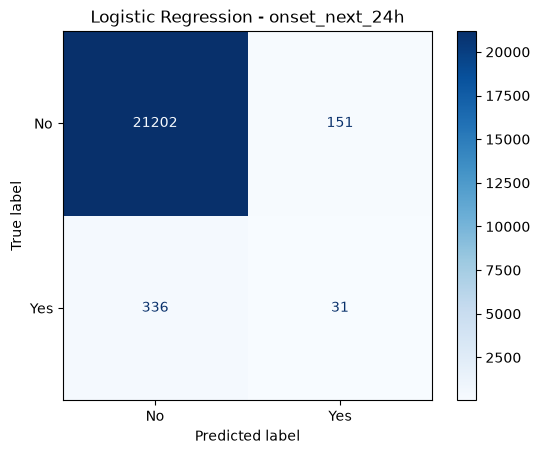

In [11]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000, class_weight="balanced")
lr.fit(X_train_s, y_train)
evaluate("Logistic Regression", lr.predict_proba(X_val_s)[:, 1], lr.predict_proba(X_test_s)[:, 1])

Model     : Naive Bayes
Threshold : 0.990
Accuracy  : 0.921
Precision : 0.164
Recall    : 0.891
F1        : 0.277
ROC-AUC   : 0.970
PR-AUC    : 0.308


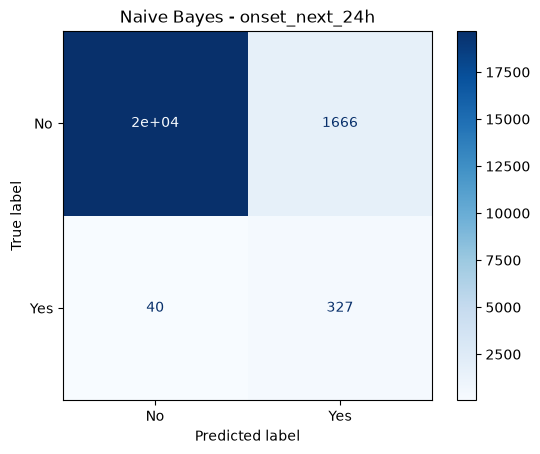

In [12]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train_s, y_train)
evaluate("Naive Bayes", nb.predict_proba(X_val_s)[:, 1], nb.predict_proba(X_test_s)[:, 1])

Model     : KNN
Threshold : 0.140
Accuracy  : 0.969
Precision : 0.186
Recall    : 0.245
F1        : 0.212
ROC-AUC   : 0.776
PR-AUC    : 0.106


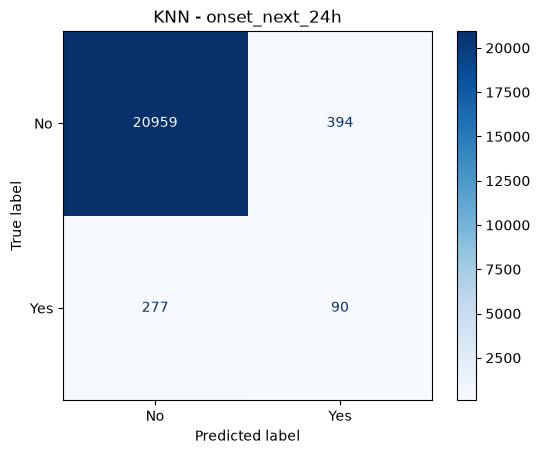

In [13]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=15, n_jobs=-1)
knn.fit(X_train_s, y_train)
evaluate("KNN", knn.predict_proba(X_val_s)[:, 1], knn.predict_proba(X_test_s)[:, 1])

Model     : Linear SVM
Threshold : 0.030
Accuracy  : 0.961
Precision : 0.195
Recall    : 0.425
F1        : 0.267
ROC-AUC   : 0.924
PR-AUC    : 0.164


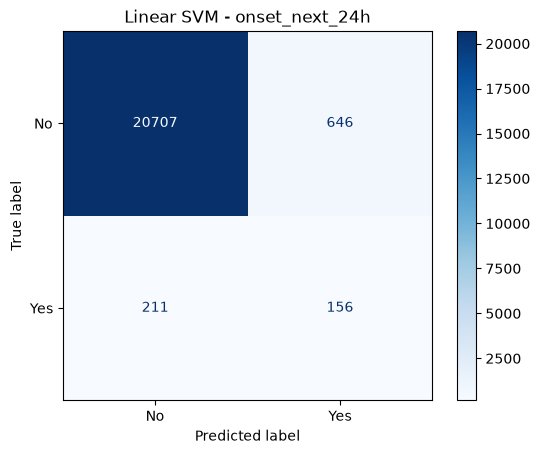

In [14]:
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

svm = CalibratedClassifierCV(LinearSVC(class_weight="balanced"), cv=3)
svm.fit(X_train_s, y_train)
evaluate("Linear SVM", svm.predict_proba(X_val_s)[:, 1], svm.predict_proba(X_test_s)[:, 1])

Model     : Decision Tree
Threshold : 0.860
Accuracy  : 0.972
Precision : 0.343
Recall    : 0.698
F1        : 0.460
ROC-AUC   : 0.835
PR-AUC    : 0.244


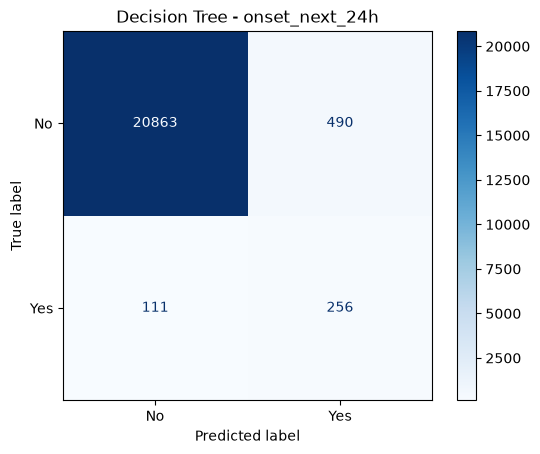

In [15]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=42)
dt.fit(X_train, y_train)
evaluate("Decision Tree", dt.predict_proba(X_val)[:, 1], dt.predict_proba(X_test)[:, 1])

Model     : Random Forest
Threshold : 0.210
Accuracy  : 0.958
Precision : 0.250
Recall    : 0.760
F1        : 0.377
ROC-AUC   : 0.956
PR-AUC    : 0.472


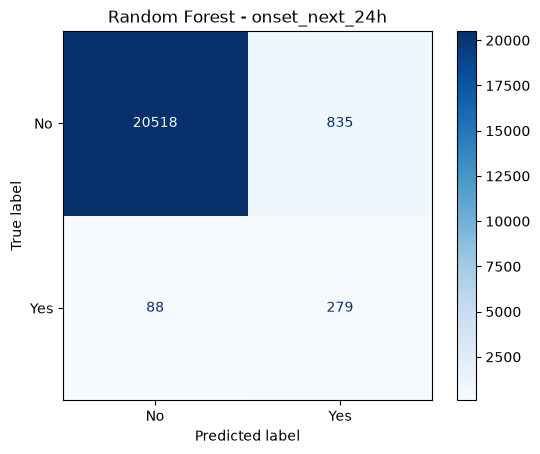

In [16]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, max_depth=12, class_weight="balanced",
                            n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
evaluate("Random Forest", rf.predict_proba(X_val)[:, 1], rf.predict_proba(X_test)[:, 1])

Model     : Extra Trees
Threshold : 0.680
Accuracy  : 0.972
Precision : 0.327
Recall    : 0.643
F1        : 0.433
ROC-AUC   : 0.972
PR-AUC    : 0.386


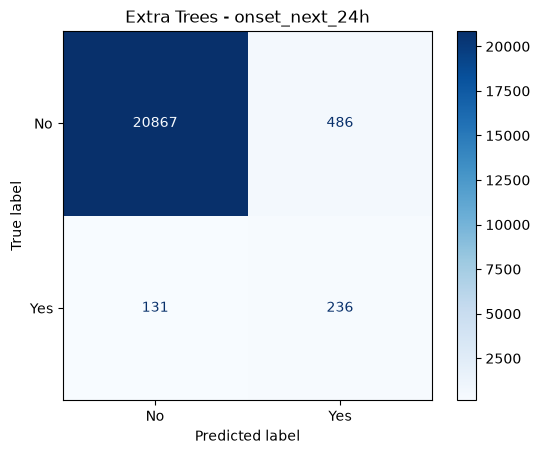

In [18]:
from sklearn.ensemble import ExtraTreesClassifier

et = ExtraTreesClassifier(n_estimators=200, max_depth=12, class_weight="balanced",
                          n_jobs=-1, random_state=42)
et.fit(X_train, y_train)
evaluate("Extra Trees", et.predict_proba(X_val)[:, 1], et.predict_proba(X_test)[:, 1])

Model     : AdaBoost
Threshold : 0.450
Accuracy  : 0.957
Precision : 0.242
Recall    : 0.728
F1        : 0.364
ROC-AUC   : 0.980
PR-AUC    : 0.513


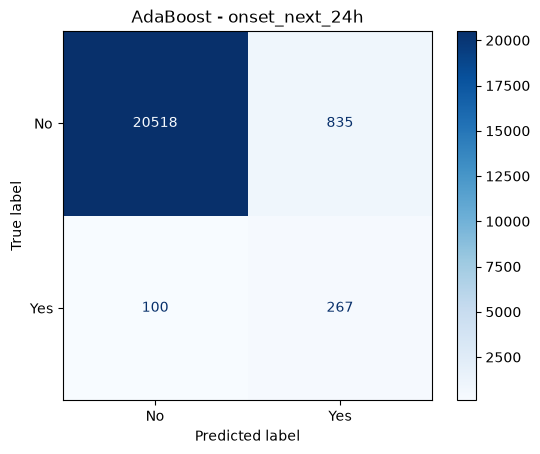

In [19]:
from sklearn.ensemble import AdaBoostClassifier

ada = AdaBoostClassifier(n_estimators=200, random_state=42)
ada.fit(X_train, y_train)
evaluate("AdaBoost", ada.predict_proba(X_val)[:, 1], ada.predict_proba(X_test)[:, 1])

Model     : Gradient Boosting
Threshold : 0.020
Accuracy  : 0.962
Precision : 0.254
Recall    : 0.643
F1        : 0.364
ROC-AUC   : 0.977
PR-AUC    : 0.555


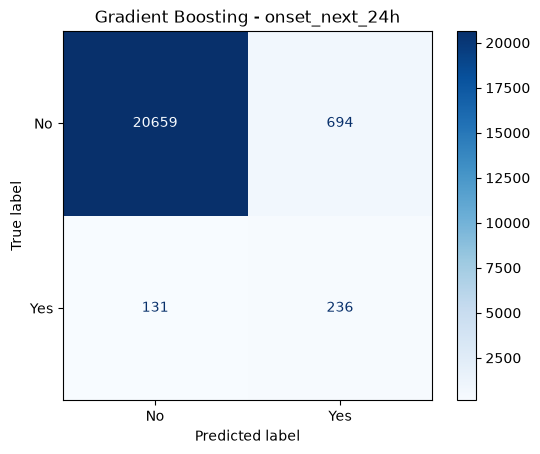

In [20]:
from sklearn.ensemble import HistGradientBoostingClassifier

gb = HistGradientBoostingClassifier(max_iter=300, class_weight="balanced", random_state=42)
gb.fit(X_train, y_train)
evaluate("Gradient Boosting", gb.predict_proba(X_val)[:, 1], gb.predict_proba(X_test)[:, 1])

Model     : Neural Network (MLP)
Threshold : 0.010
Accuracy  : 0.975
Precision : 0.363
Recall    : 0.605
F1        : 0.454
ROC-AUC   : 0.973
PR-AUC    : 0.465


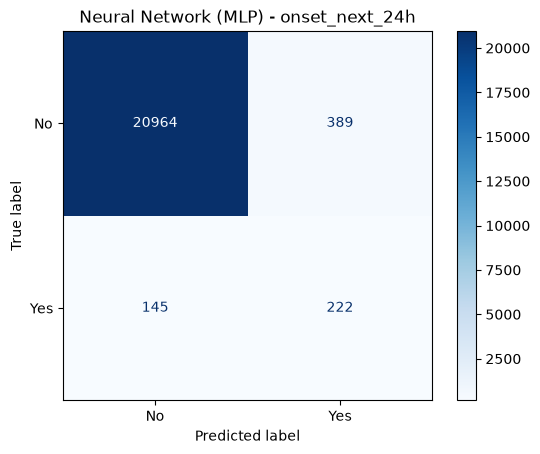

In [21]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=200, early_stopping=True, random_state=42)
mlp.fit(X_train_s, y_train)
evaluate("Neural Network (MLP)", mlp.predict_proba(X_val_s)[:, 1], mlp.predict_proba(X_test_s)[:, 1])

Model     : XGBoost
Threshold : 0.010
Accuracy  : 0.958
Precision : 0.241
Recall    : 0.706
F1        : 0.360
ROC-AUC   : 0.973
PR-AUC    : 0.503


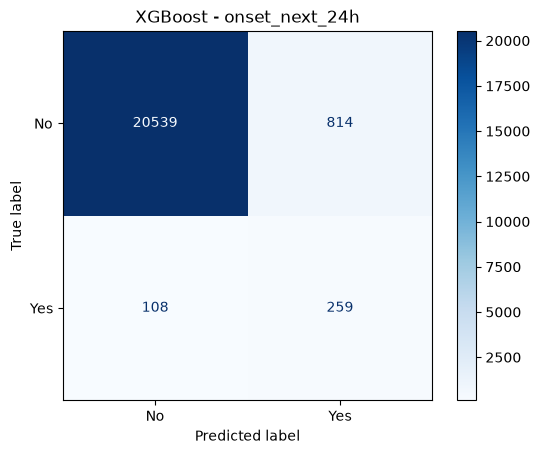

In [22]:
from xgboost import XGBClassifier

ratio = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05,
                    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=ratio,
                    eval_metric="logloss", n_jobs=-1, random_state=42)
xgb.fit(X_train, y_train)
evaluate("XGBoost", xgb.predict_proba(X_val)[:, 1], xgb.predict_proba(X_test)[:, 1])

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Decision Tree,0.86,0.972,0.343,0.698,0.460,0.835,0.244
1,Neural Network (MLP),0.01,0.975,0.363,0.605,0.454,0.973,0.465
2,Extra Trees,0.68,0.972,0.327,0.643,0.433,0.972,0.386
3,Random Forest,0.21,0.958,0.250,0.760,0.377,0.956,0.472
4,Gradient Boosting,0.02,0.962,0.254,0.643,0.364,0.977,0.555
5,AdaBoost,0.45,0.957,0.242,0.728,0.364,0.980,0.513
6,XGBoost,0.01,0.958,0.241,0.706,0.360,0.973,0.503
7,Naive Bayes,0.99,0.921,0.164,0.891,0.277,0.970,0.308
8,Linear SVM,0.03,0.961,0.195,0.425,0.267,0.924,0.164
9,KNN,0.14,0.969,0.186,0.245,0.212,0.776,0.106


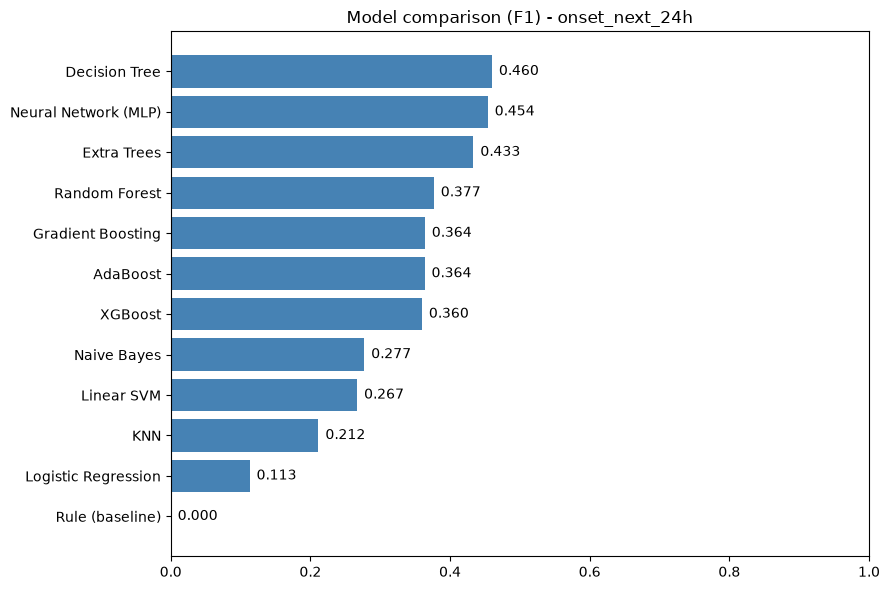

In [23]:
table = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
display(table.round(3))

t = table.sort_values("F1")
plt.figure(figsize=(9, 6))
plt.barh(t["Model"], t["F1"], color="steelblue")
for i, v in enumerate(t["F1"]):
    plt.text(v + 0.01, i, f"{v:.3f}", va="center")
plt.xlim(0, 1)
plt.title(f"Model comparison (F1) - {TARGET}")
plt.tight_layout()
plt.show()

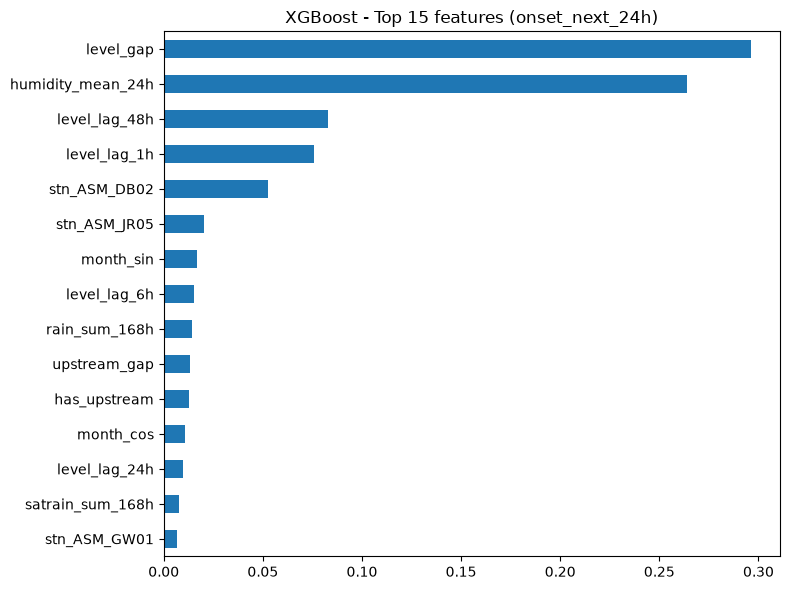

In [24]:
imp = pd.Series(xgb.feature_importances_, index=features).sort_values(ascending=False).head(15)
imp.sort_values().plot(kind="barh", figsize=(8, 6), title=f"XGBoost - Top 15 features ({TARGET})")
plt.tight_layout()
plt.show()

In [25]:
xgb_t = table.loc[table["Model"] == "XGBoost", "Threshold"].iloc[0]
joblib.dump({"model": xgb, "threshold": xgb_t, "features": features}, f"../models/xgb_{TARGET}.pkl")
table.to_csv(f"../models/results_{TARGET}.csv", index=False)
print("Saved!")

Saved!
